## 1. Data Loading

In this section, we load the dataset and inspect its basic structure.

In [1]:
import pandas as pd

### Loading the Dataset

We load the hourly bike rental data into a Pandas DataFrame.

In [2]:
data = pd.read_csv('../data/raw/hour.csv')

In [3]:
data.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Dataset Overview

We inspect the dataset dimensions and column names to understand its structure.

In [4]:
data.shape

(17379, 17)

In [5]:
data.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

### Initial Dataset Overview

The dataset contains 17,379 hourly records and 17 columns. It includes time, weather, and rental information.

The target variable is `cnt`. The columns `casual` and `registered` will be excluded from the model features because their sum equals the target.

### Feature Description

| Feature | Description |
|---|---|
| `instant` | Record index |
| `dteday` | Date of the record |
| `season` | Season of the year |
| `yr` | Year |
| `mnth` | Month |
| `hr` | Hour of the day |
| `holiday` | Indicates whether the day is a holiday |
| `weekday` | Day of the week |
| `workingday` | Indicates whether the day is a working day |
| `weathersit` | Weather conditions category |
| `temp` | Normalized temperature |
| `atemp` | Normalized feels-like temperature |
| `hum` | Normalized humidity |
| `windspeed` | Normalized wind speed |
| `casual` | Rentals by casual users |
| `registered` | Rentals by registered users |
| `cnt` | Total number of bike rentals (target variable) |

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


### Data Quality Checks
In this section, we check the dataset for missing values and duplicate records to ensure data quality.

In [7]:
data.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

###Statistical Analysis
In this section, we examine the statistical properties of numerical features to understand their distributions and identify potential patterns.

In [9]:
data.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### Initial Observations

The initial statistical analysis reveals several interesting characteristics of the dataset:

- The average hourly rental count (`cnt`) is approximately 189, while the median is 142. This suggests that the distribution may be right-skewed.
- The number of rentals varies significantly, ranging from 1 to 977 per hour.
- Temperature (`temp`), feels-like temperature (`atemp`), humidity (`hum`), and wind speed (`windspeed`) are normalized values between 0 and 1 (with some variation in the wind speed range).
- The dataset covers all 24 hours of the day, with `hr` ranging from 0 to 23.
- Several features, such as `season`, `weekday`, and `weathersit`, represent categories rather than continuous numerical measurements.

###Target Variable Distribution
In this section, we visualize the distribution of the target variable to understand hourly bike rental demand.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

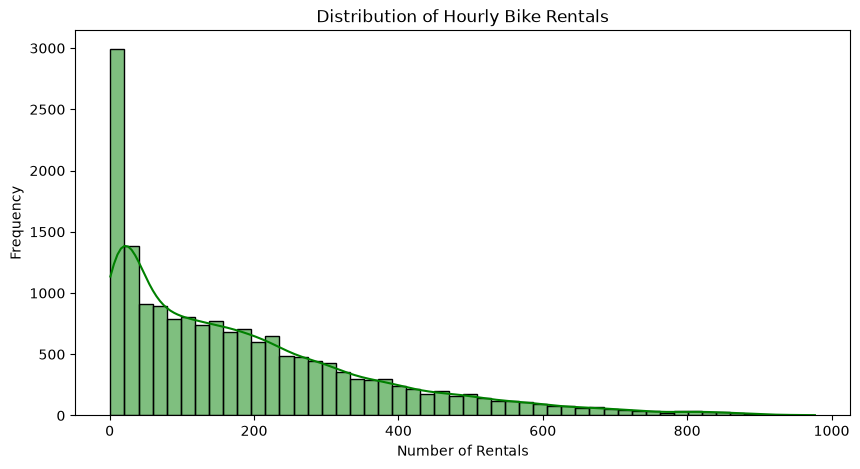

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='cnt', bins=50, kde=True, color='green')

plt.title('Distribution of Hourly Bike Rentals')
plt.xlabel('Number of Rentals')
plt.ylabel('Frequency')

plt.show()

The target variable cnt has a right-skewed distribution. Most hourly rental counts are relatively low, while high rental counts occur less frequently. The mean (189.46) is higher than the median (142), which is consistent with the observed distribution.

###Hourly Rental Demand
In this section, we analyze how hourly bike rental demand changes throughout the day by examining the average number of rentals for each hour.

In [12]:
hourly_demand = data.groupby('hr')['cnt'].mean().reset_index()

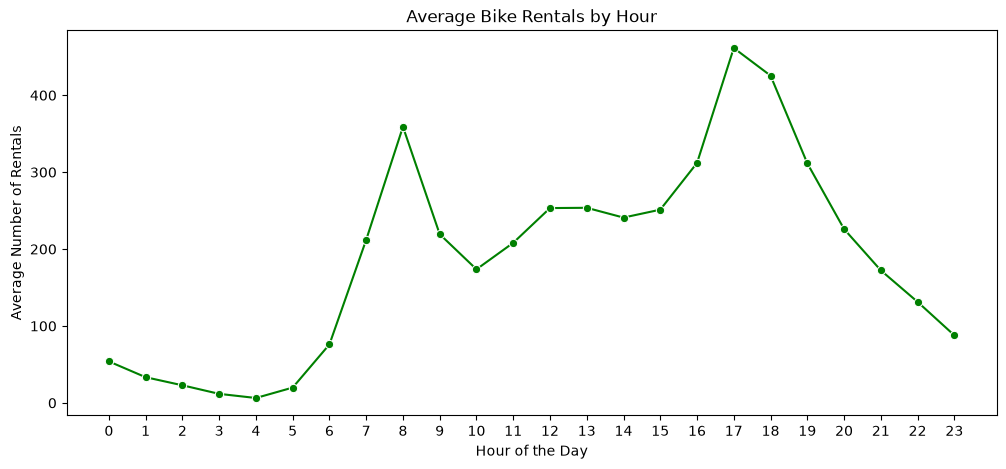

In [13]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=hourly_demand, x='hr', y='cnt', marker='o', color='green')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(24))

plt.show()

### Weekday Rental Demand

In this section, we analyze how average bike rental demand varies across different days of the week.

#### Average Rentals by Day of the Week

We calculate the average number of bike rentals for each day of the week and visualize the results to identify differences in rental demand.

In [14]:
weekday_demand = data.groupby('weekday')['cnt'].mean().reset_index()

In [15]:
weekday_names = {
    0: 'Sunday',
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday'
}

In [16]:
weekday_demand['weekday_name'] = weekday_demand['weekday'].map(weekday_names)

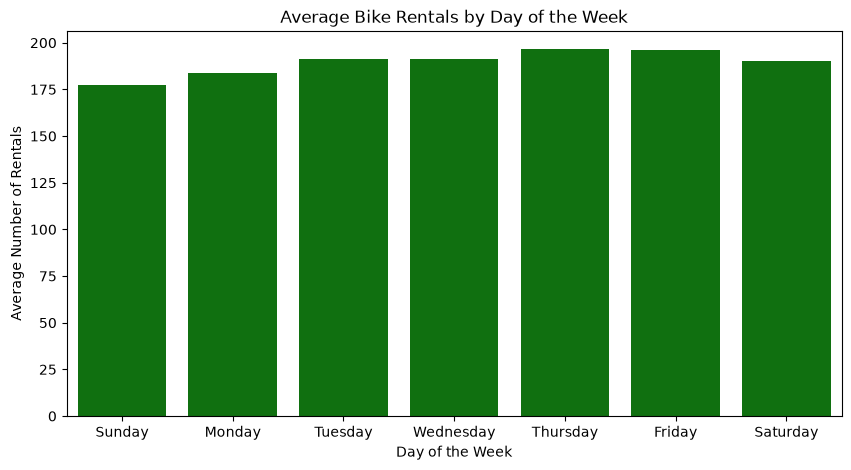

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(data=weekday_demand, x='weekday_name', y='cnt', color='green')

plt.title('Average Bike Rentals by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Number of Rentals')

plt.show()

The average hourly rental demand remains relatively stable across the week. Thursday and Friday show the highest average rental counts, while Sunday has the lowest. The differences between days are relatively small compared to the hourly variations observed earlier.

### Seasonal Rental Demand

In this section, we analyze how average bike rental demand varies across different seasons of the year.

#### Average Rentals by Season

We calculate the average number of bike rentals for each season and visualize the results to identify seasonal patterns in rental demand.

In [19]:
seasonal_demand = data.groupby('season')['cnt'].mean().reset_index()

In [20]:
season_names = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

seasonal_demand['season_name'] = seasonal_demand['season'].map(season_names)

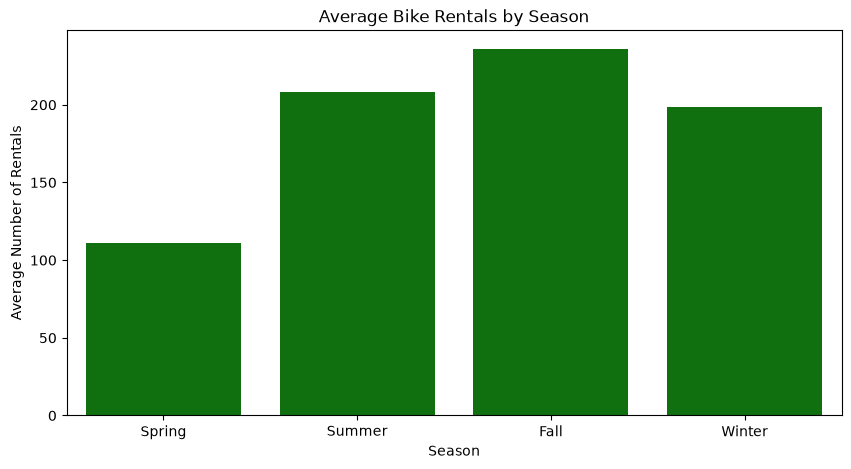

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=seasonal_demand,
    x='season_name',
    y='cnt',
    order=['Spring', 'Summer', 'Fall', 'Winter'], color='green'
)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Number of Rentals')

plt.show()

The analysis reveals clear seasonal differences in bike rental demand. Fall has the highest average rental count, followed by Summer and Winter. Spring has the lowest demand. These results suggest that the season may be an important feature for predicting bike rental demand.